# CA4
- Johannes Husevåg Standal
- Rozalia Anna Ciupka

### Imports


In [59]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import seaborn as sns
import matplotlib.pyplot as plt

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Pipelines and dimension reduction
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Model selection
from sklearn.model_selection import train_test_split, GridSearchCV

# Evaluation
from sklearn.metrics import f1_score, accuracy_score, ConfusionMatrixDisplay

### Read the data

In [60]:
df_train = pd.read_csv("trainCA4DAT200.csv")
df_submission = pd.read_csv("testCA4DAT200.csv")


### Data exploration and visualisation


In [61]:
# Check for missing values, we have none
print(f"missing values in training data: {df_train.isna().sum()}")

missing values in training data: CustomerId              0
State                   0
AccountLength           0
AreaCode                0
InternationalPlan       0
VoiceMailPlan           0
NumVoiceMailMessages    0
DayMinutes              0
DayCalls                0
DayCharge               0
EveMinutes              0
EveCalls                0
EveCharge               0
NightMinutes            0
NightCalls              0
NightCharge             0
IntlMinutes             0
IntlCalls               0
IntlCharge              0
CustomerServiceCalls    0
Churn                   0
dtype: int64


In [62]:
# Check for duplicate rows, we have none
print("Duplicate rows:", df_train.duplicated().sum())

Duplicate rows: 0


In [63]:
# Class distribution in the training data
print(df_train["Churn"].value_counts(normalize=True))

Churn
0    0.858571
1    0.141429
Name: proportion, dtype: float64


In [64]:
# correlation map from numerical features, modified code from lecture 12
# df_numeric = df_train.drop(columns=["CustomerId", "State", "InternationalPlan", "VoiceMailPlan"])

# plt.figure(figsize=(20,20))
# sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm')
# plt.title("Correlation map from training data")

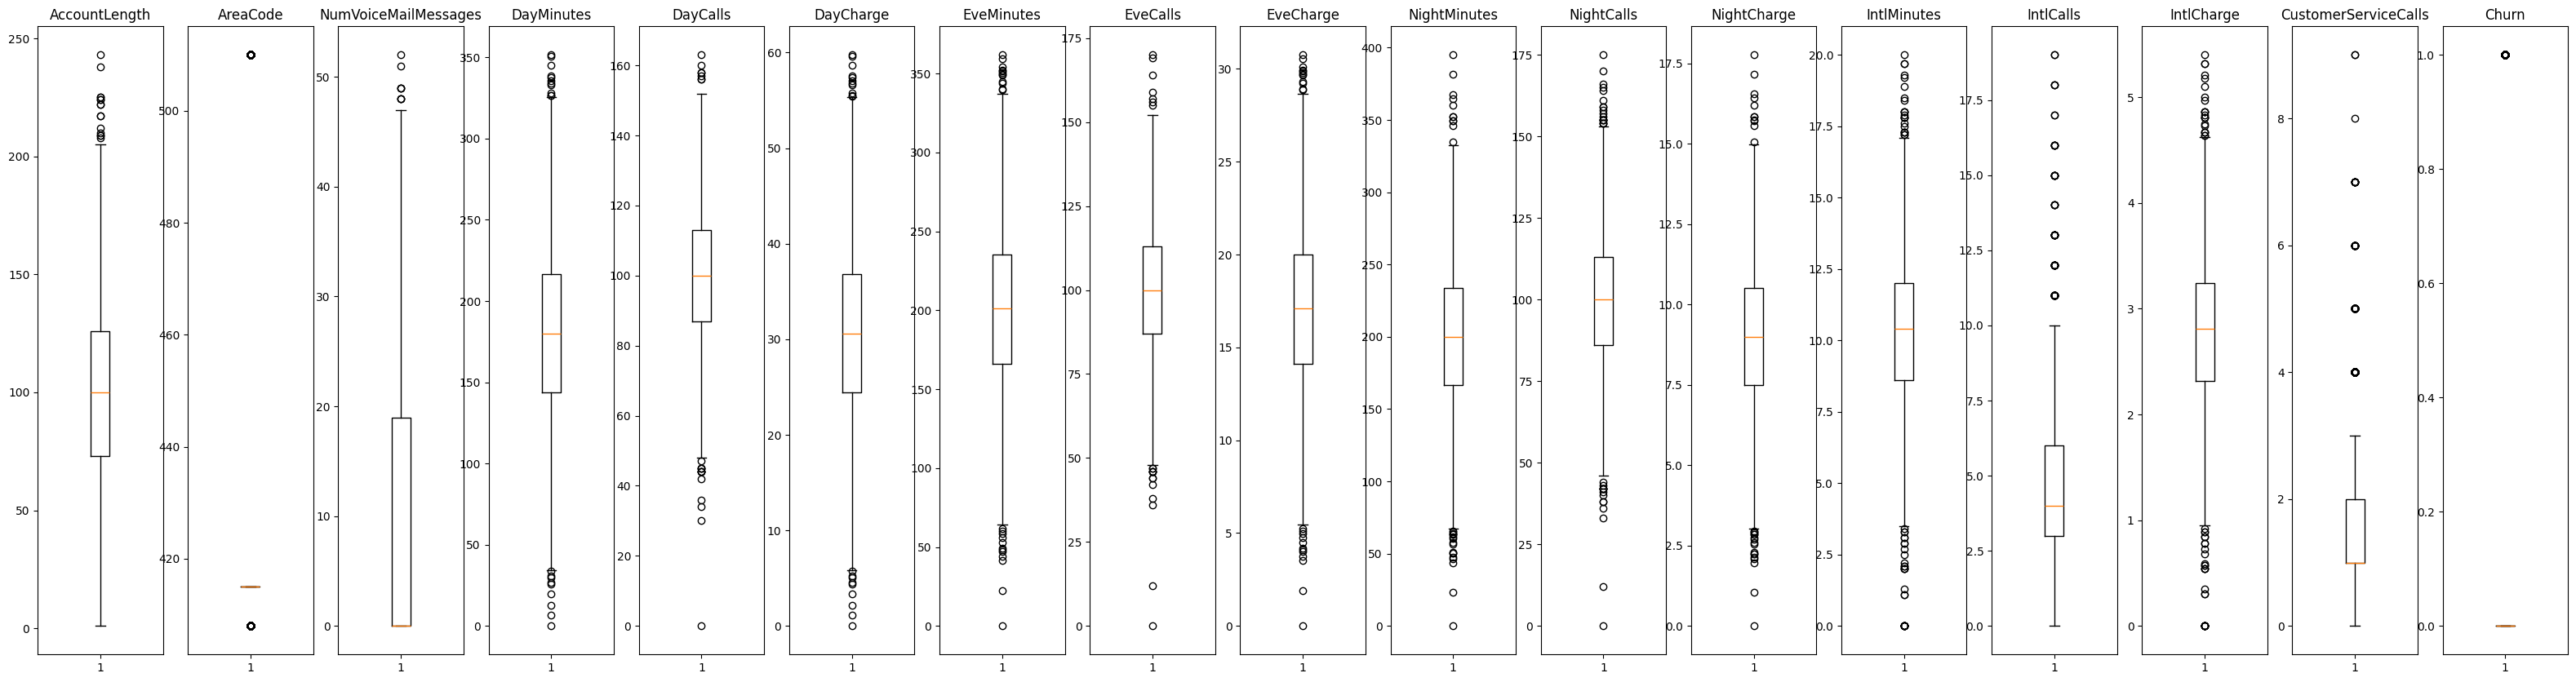

In [65]:
# whisker plots to check for outliers, modified code from lecture 12
fig, ax = plt.subplots(1, len(df_numeric.columns), figsize=(40,10))

for i, column in enumerate(df_numeric.columns):
    ax[i].set_title(column)
    ax[i].boxplot(df_numeric[column])

In [66]:
# Pairplots to check for relationships between features
# sns.pairplot(df_numeric,  hue="Churn", plot_kws={'s':5})

### Data cleaning


In [67]:
# Dropping correlated values

df_train = df_train.drop(['DayMinutes', 'EveMinutes', 'NightMinutes', 'IntlMinutes'], axis=1)
df_submission =df_submission.drop(['DayMinutes', 'EveMinutes', 'NightMinutes', 'IntlMinutes'], axis=1)

### Data exploration and visualisation after cleaning

In [68]:
# categorize nominal features
df_train["InternationalPlan"] = df_train["InternationalPlan"].map({"yes": 1, "no": 0})
df_train["VoiceMailPlan"] = df_train["VoiceMailPlan"].map({"yes": 1, "no": 0})

# categorical features
state_ohe = OneHotEncoder(drop='first', sparse_output=False)
out = state_ohe.fit_transform(df_train[['State']]) # expects a 2D array
# turn into data frame
df_ohe = pd.DataFrame(out, columns=state_ohe.get_feature_names_out())

# combine back into the original data frame
df_train = pd.concat([df_train.drop(['State'], axis=1), df_ohe], axis=1)

df_train.head()

x_train = df_train.drop(['Churn', 'CustomerId'], axis=1)
y_train = df_train['Churn']


### Data split

In [69]:
X_train, X_test, Y_train, Y_test = train_test_split(x_train, y_train, test_size=0.4, random_state=42, stratify=y_train) 

### Pipeline
Preprocessing → Evaluating models/hyperparameters (cross-validation)


In [72]:
# RandomForest 

pipeline = Pipeline([
    ('classifier', RandomForestClassifier())
])

param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 10],
    'classifier__min_samples_split': [2, 5, 10],
}

grid = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=5
)

grid.fit(X_train, Y_train)
RF_best_model = grid.best_estimator_
RF_best_model.fit(X_train, Y_train)
RF_best_model.score(X_test, Y_test)


0.9307142857142857

In [80]:
# LogisticRegression

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression())
])

param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__max_iter': [2000],
    'classifier__penalty': ['l1', 'l2', 'elasticnet'],
    'classifier__solver': ['saga', 'lbfgs']
}

grid = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=5
)

grid.fit(X_train, Y_train)
LR_best_model = grid.best_estimator_
LR_best_model.fit(X_train, Y_train)
LR_best_model.score(X_test, Y_test)

c:\Users\rozal\Desktop\Studia\DAT200\CA2.venv\lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
90 fits failed out of a total of 180.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\rozal\Desktop\Studia\DAT200\CA2.venv\lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\rozal\Desktop\Studia\DAT200\CA2.venv\lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\rozal\Desktop\Studia\DAT200\CA2.venv\lib\site-packages\sklearn\pipeline.py", line 663, i

0.865

### Kaggle submission

### Data cleaning


### Data exploration and visualisation after cleaning

### Pipeline
Preprocessing → Evaluating models/hyperparameters (cross-validation)


### Kaggle submission